In [1]:
!pip install pandas matplotlib

import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
BASE_REUSE = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data"   

BASE_NO_REUSE = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data"

def load_and_align(metric_name):
    reuse_path = f"{BASE_REUSE}/{metric_name}.csv"
    no_reuse_path = f"{BASE_NO_REUSE}/{metric_name}.csv"

    df_reuse = pd.read_csv(reuse_path)
    df_no_reuse = pd.read_csv(no_reuse_path)

    df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
    df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

    # normalize time to t=0 (seconds)
    df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
    df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

    return df_reuse, df_no_reuse

In [ ]:
#system_cpu_usage


import pandas as pd
import matplotlib.pyplot as plt

# File paths — update to your actual CSVs
reuse_file = "data/Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/system_cpu_usage.csv"
no_reuse_file = "data/no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/system_cpu_usage.csv"

# Load CSVs
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# Convert timestamps and normalize to t=0
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# Plot both reuse and no-reuse in one scatter plot
plt.figure(figsize=(12,6))
plt.scatter(df_reuse["t_sec"], df_reuse["system_cpu_usage"], alpha=0.5, color='blue', s=20, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["system_cpu_usage"], alpha=0.5, color='red', s=20, label='No-Reuse')

plt.xlabel("Time since start [s]")
plt.ylabel("system_cpu_usage (cpu_time_seconds)")
plt.title("System CPU usage per pod: reuse vs no-reuse")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/system_cpu_usage.csv'

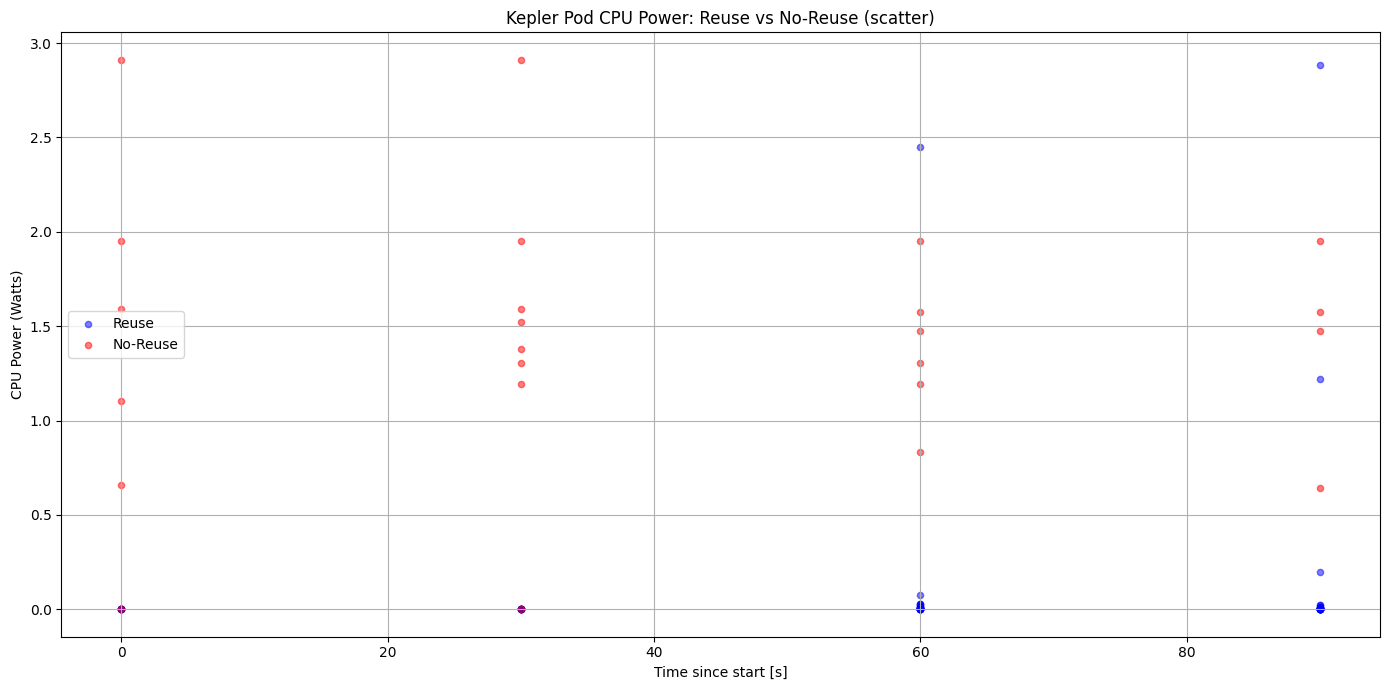

In [53]:
#kepler_pod_cpu_power_watts

import pandas as pd
import matplotlib.pyplot as plt

# File paths
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/kepler_pod_cpu_power_watts.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/kepler_pod_cpu_power_watts.csv"

# Load CSVs
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)
# Convert timestamp and normalize to t=0
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# Scatter plot
plt.figure(figsize=(14,7))

# Reuse pods (blue dots)
plt.scatter(df_reuse["t_sec"], df_reuse["kepler_pod_cpu_power_watts"], 
            color='blue', alpha=0.5, s=20, label='Reuse')

# No-reuse pods (red dots)
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["kepler_pod_cpu_power_watts"], 
            color='red', alpha=0.5, s=20, label='No-Reuse')

plt.xlabel("Time since start [s]")
plt.ylabel("CPU Power (Watts)")
plt.title("Kepler Pod CPU Power: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

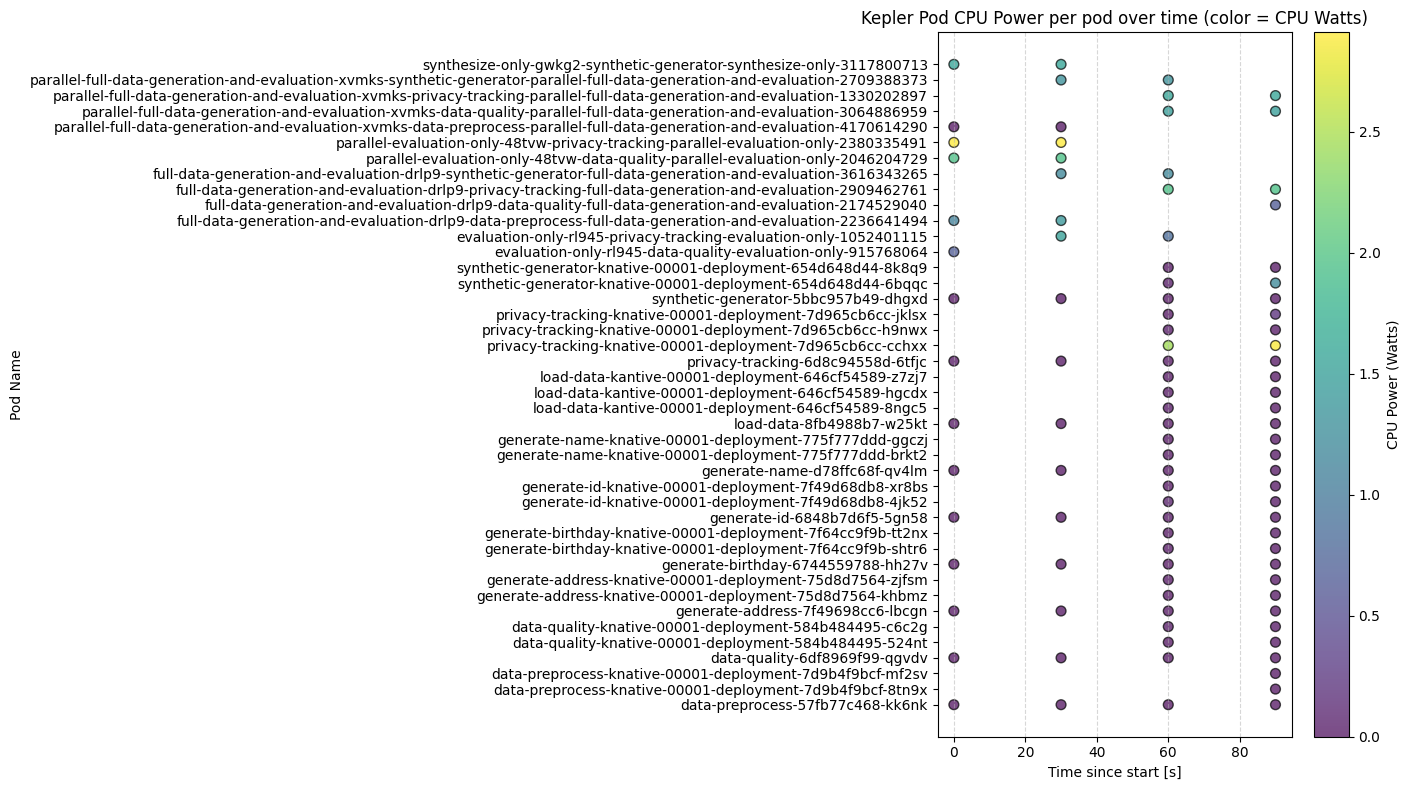

In [52]:
#kepler_pod_cpu_power_watts

import pandas as pd
import matplotlib.pyplot as plt

# File paths
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/kepler_pod_cpu_power_watts.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/kepler_pod_cpu_power_watts.csv"

# Load CSVs
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# Convert timestamp and normalize to t=0
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# Combine reuse and no-reuse for one plot
df_reuse["setup"] = "Reuse"
df_no_reuse["setup"] = "No-Reuse"
df_all = pd.concat([df_reuse, df_no_reuse], ignore_index=True)

# Map pod_name to categorical index for Y-axis
pod_names = df_all["pod_name"].unique()
pod_map = {pod: i for i, pod in enumerate(pod_names)}
df_all["pod_idx"] = df_all["pod_name"].map(pod_map)

# Plot
plt.figure(figsize=(14,8))
scatter = plt.scatter(
    df_all["t_sec"], df_all["pod_idx"], 
    c=df_all["kepler_pod_cpu_power_watts"], 
    cmap="viridis", s=50, alpha=0.7, edgecolors='k'
)

plt.yticks(list(pod_map.values()), list(pod_map.keys()))
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Name")
plt.title("Kepler Pod CPU Power per pod over time (color = CPU Watts)")
cbar = plt.colorbar(scatter)
cbar.set_label("CPU Power (Watts)")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


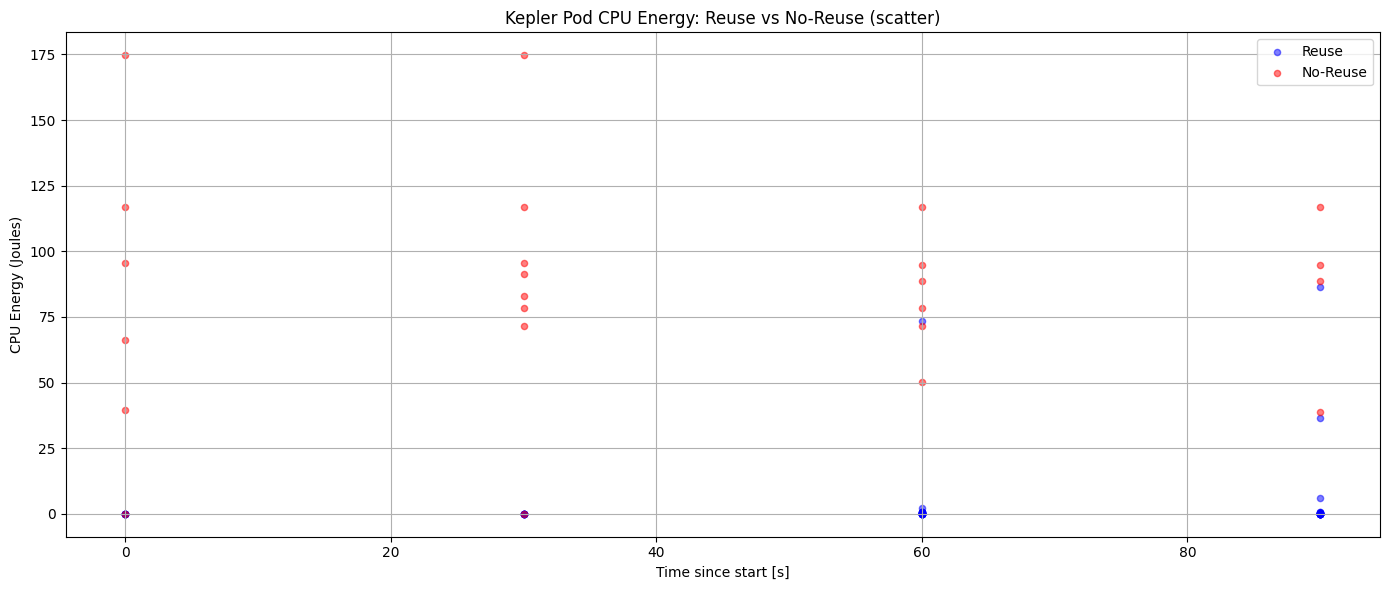

In [51]:
# kepler_pod_cpu_energy_joules

# File paths
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/kepler_pod_cpu_energy_joules.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/kepler_pod_cpu_energy_joules.csv"

# Load CSVs
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# Convert timestamp and normalize to t=0
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- 1. Scatter plot WITHOUT pod names ---
plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["kepler_pod_cpu_energy_joules"], 
            color='blue', alpha=0.5, s=20, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["kepler_pod_cpu_energy_joules"], 
            color='red', alpha=0.5, s=20, label='No-Reuse')
plt.xlabel("Time since start [s]")
plt.ylabel("CPU Energy (Joules)")
plt.title("Kepler Pod CPU Energy: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

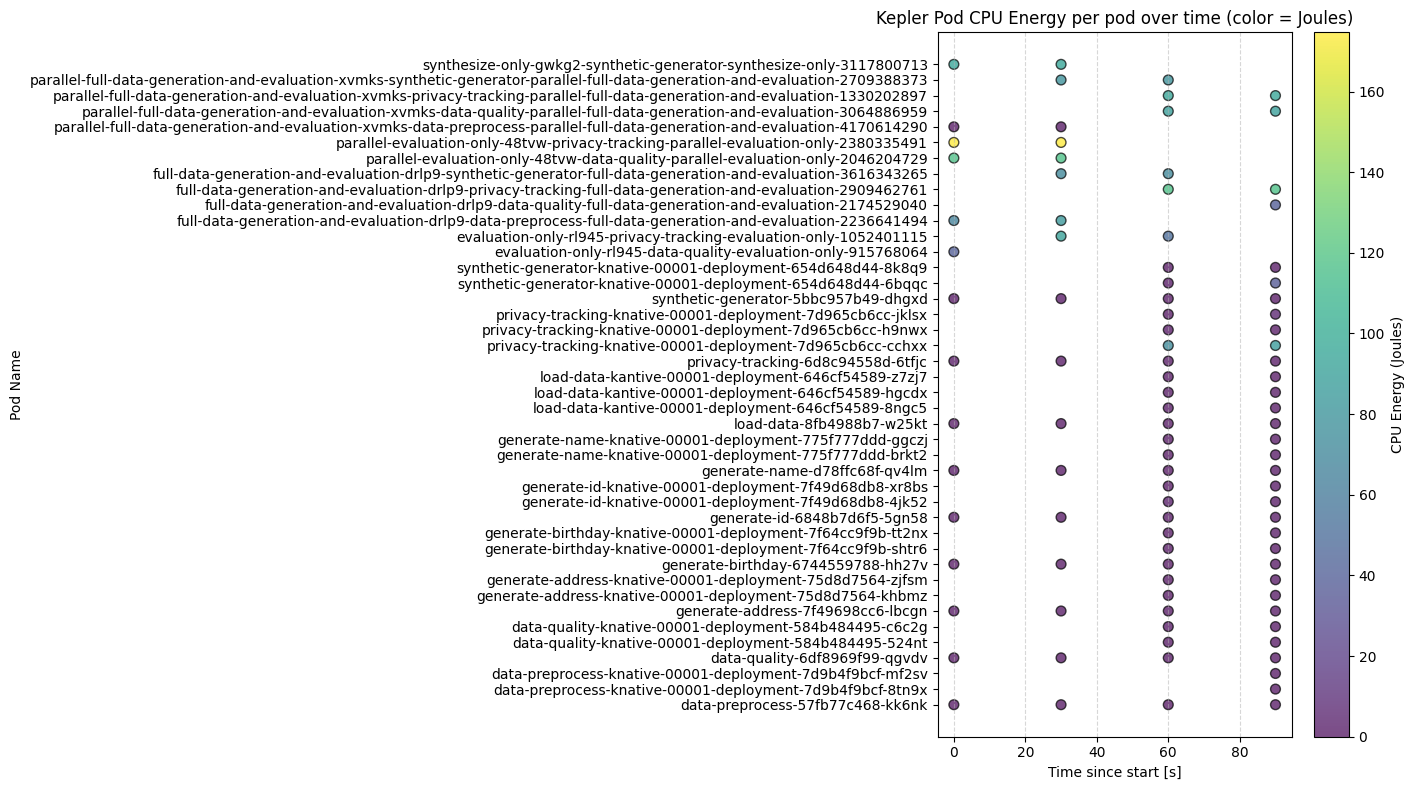

In [50]:
# kepler_pod_cpu_energy_joules

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/kepler_pod_cpu_energy_joules.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/kepler_pod_cpu_energy_joules.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Add setup column and combine ---
df_reuse["setup"] = "Reuse"
df_no_reuse["setup"] = "No-Reuse"
df_all = pd.concat([df_reuse, df_no_reuse], ignore_index=True)

# --- Map pod_name to categorical index for Y-axis ---
pod_names = df_all["pod_name"].unique()
pod_map = {pod: i for i, pod in enumerate(pod_names)}
df_all["pod_idx"] = df_all["pod_name"].map(pod_map)

# --- Scatter plot ---
plt.figure(figsize=(14,8))
scatter = plt.scatter(
    df_all["t_sec"], df_all["pod_idx"], 
    c=df_all["kepler_pod_cpu_energy_joules"], 
    cmap="viridis", s=50, alpha=0.7, edgecolors='k'
)
plt.yticks(list(pod_map.values()), list(pod_map.keys()))
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Name")
plt.title("Kepler Pod CPU Energy per pod over time (color = Joules)")
cbar = plt.colorbar(scatter)
cbar.set_label("CPU Energy (Joules)")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


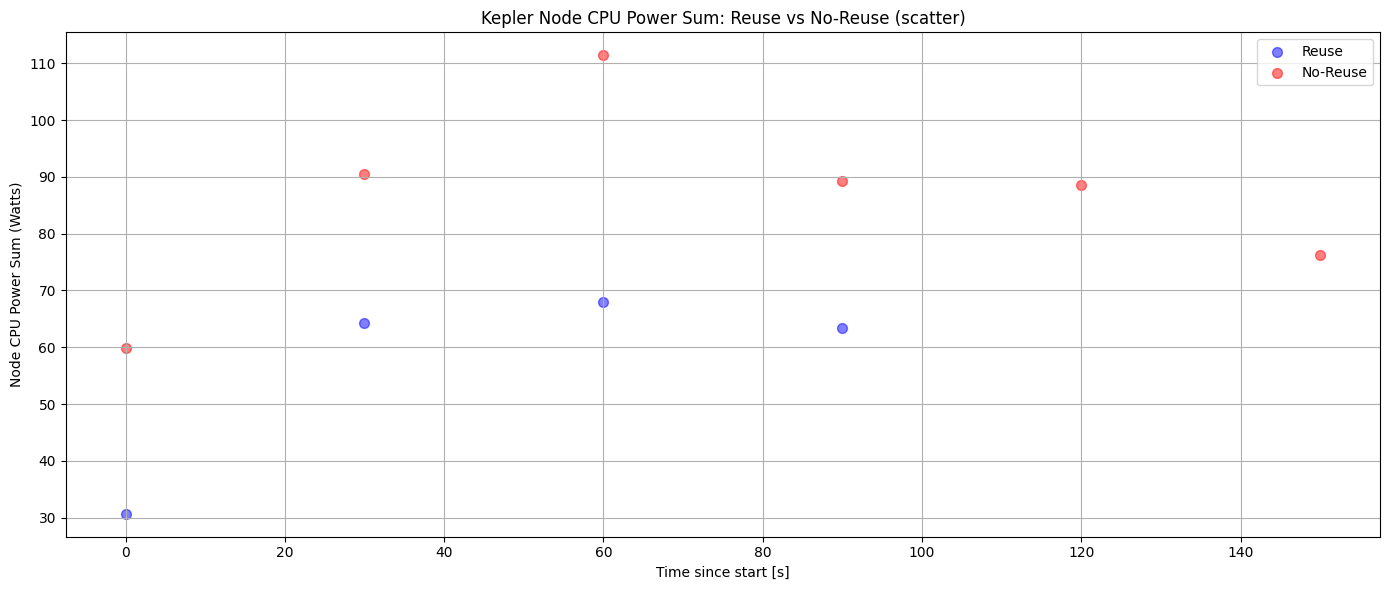

In [49]:
# kepler_node_cpu_power_sum

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/kepler_node_cpu_power_sum.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/kepler_node_cpu_power_sum.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Scatter plot: reuse vs no-reuse ---
plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["kepler_node_cpu_power_sum"], 
            color='blue', alpha=0.5, s=50, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["kepler_node_cpu_power_sum"], 
            color='red', alpha=0.5, s=50, label='No-Reuse')

plt.xlabel("Time since start [s]")
plt.ylabel("Node CPU Power Sum (Watts)")
plt.title("Kepler Node CPU Power Sum: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

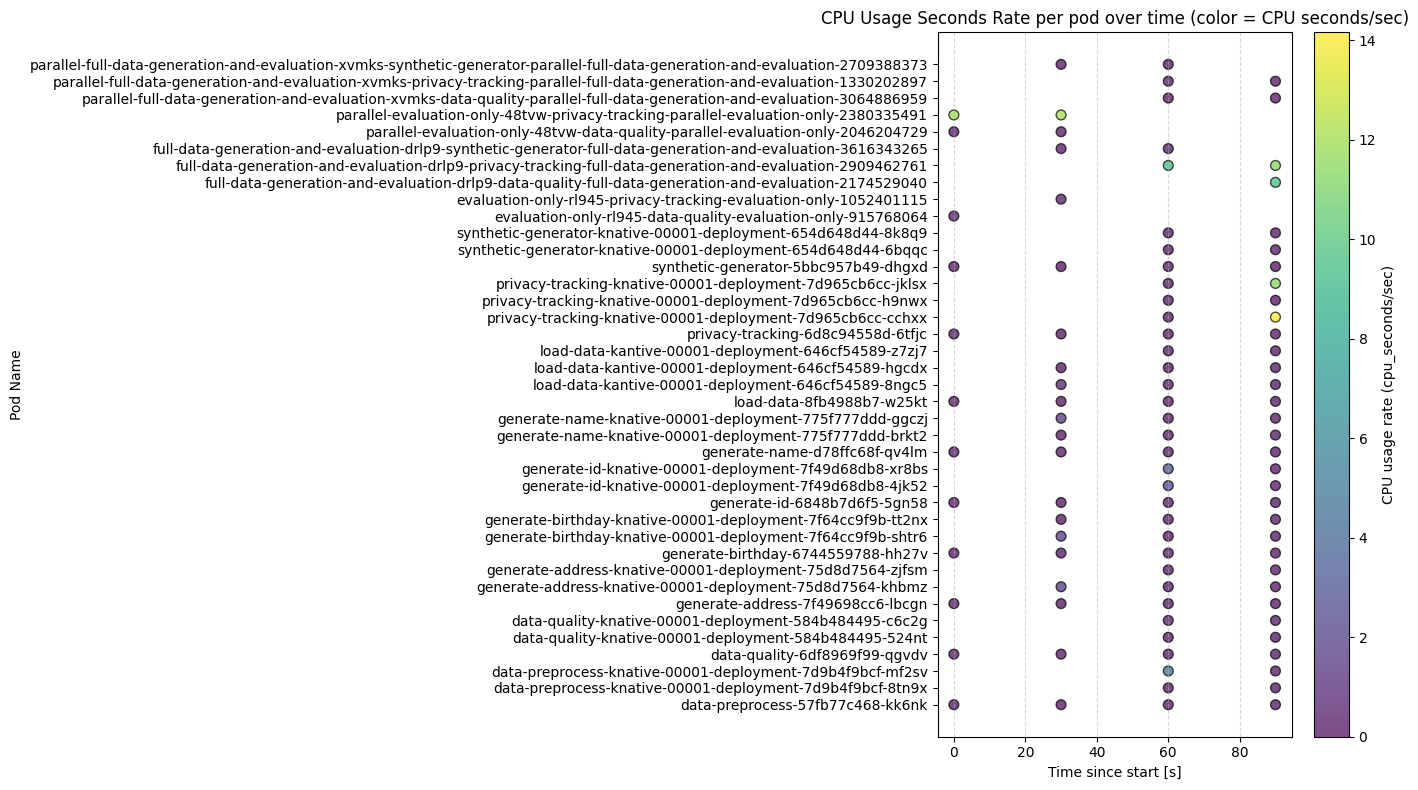

In [48]:
# cpu_usage_second_rate

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/cpu_usage_seconds_rate.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/cpu_usage_seconds_rate.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Add setup column and combine ---
df_reuse["setup"] = "Reuse"
df_no_reuse["setup"] = "No-Reuse"
df_all = pd.concat([df_reuse, df_no_reuse], ignore_index=True)

# --- Map pod to categorical Y-axis ---
pod_names = df_all["pod"].unique()
pod_map = {pod: i for i, pod in enumerate(pod_names)}
df_all["pod_idx"] = df_all["pod"].map(pod_map)

# --- Scatter plot ---
plt.figure(figsize=(14,8))
scatter = plt.scatter(
    df_all["t_sec"], df_all["pod_idx"], 
    c=df_all["cpu_usage_seconds_rate"], 
    cmap="viridis", s=50, alpha=0.7, edgecolors='k'
)
plt.yticks(list(pod_map.values()), list(pod_map.keys()))
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Name")
plt.title("CPU Usage Seconds Rate per pod over time (color = CPU seconds/sec)")
cbar = plt.colorbar(scatter)
cbar.set_label("CPU usage rate (cpu_seconds/sec)")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


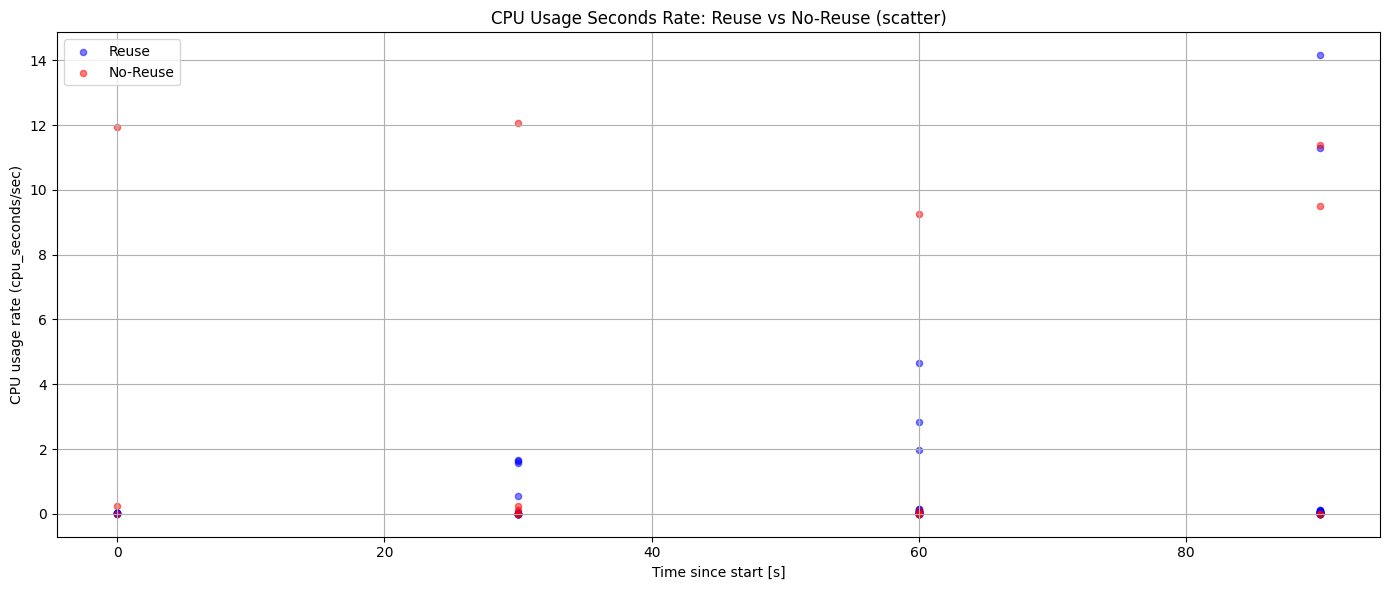

In [47]:
# cpu_usage_second_rate
import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/cpu_usage_seconds_rate.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/cpu_usage_seconds_rate.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- --- 1. Scatter WITHOUT pod names ---
plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["cpu_usage_seconds_rate"], 
            color='blue', alpha=0.5, s=20, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["cpu_usage_seconds_rate"], 
            color='red', alpha=0.5, s=20, label='No-Reuse')
plt.xlabel("Time since start [s]")
plt.ylabel("CPU usage rate (cpu_seconds/sec)")
plt.title("CPU Usage Seconds Rate: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


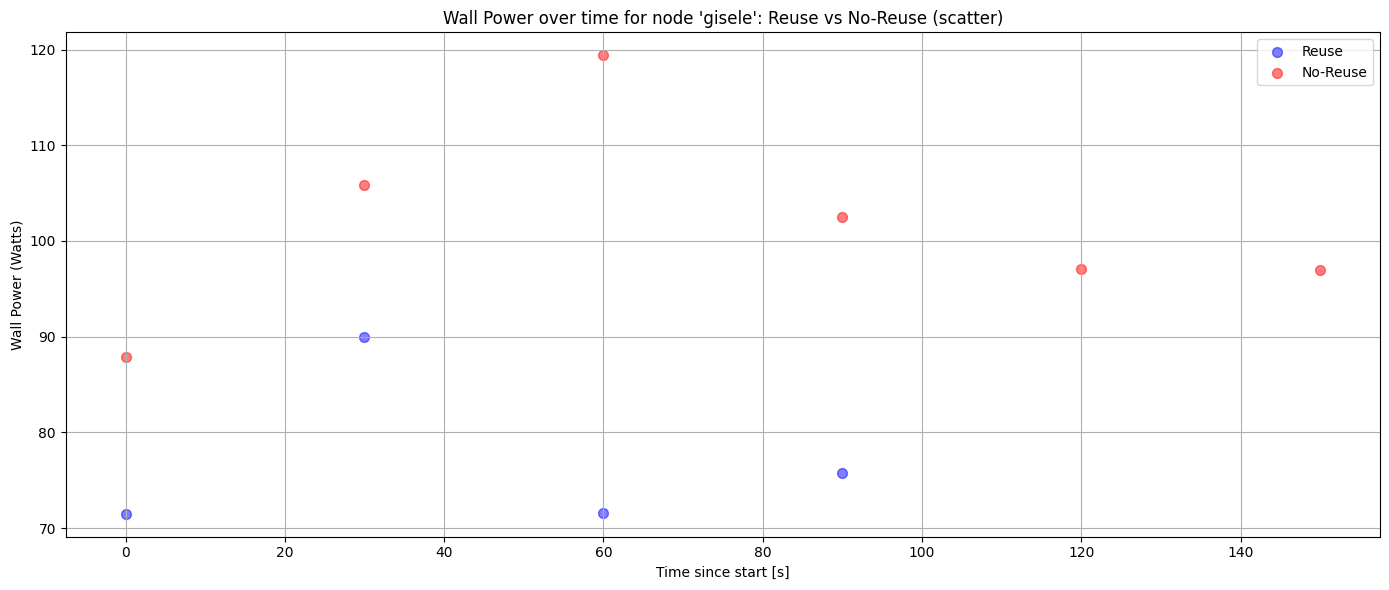

In [46]:
# wall_power

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/wall_power.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/wall_power.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Filter for node = gisele ---
df_reuse = df_reuse[df_reuse["node"] == "gisele"]
df_no_reuse = df_no_reuse[df_no_reuse["node"] == "gisele"]

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Scatter plot: wall power ---
plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["wall_power"], 
            color='blue', alpha=0.5, s=50, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["wall_power"], 
            color='red', alpha=0.5, s=50, label='No-Reuse')

plt.xlabel("Time since start [s]")
plt.ylabel("Wall Power (Watts)")
plt.title("Wall Power over time for node 'gisele': Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


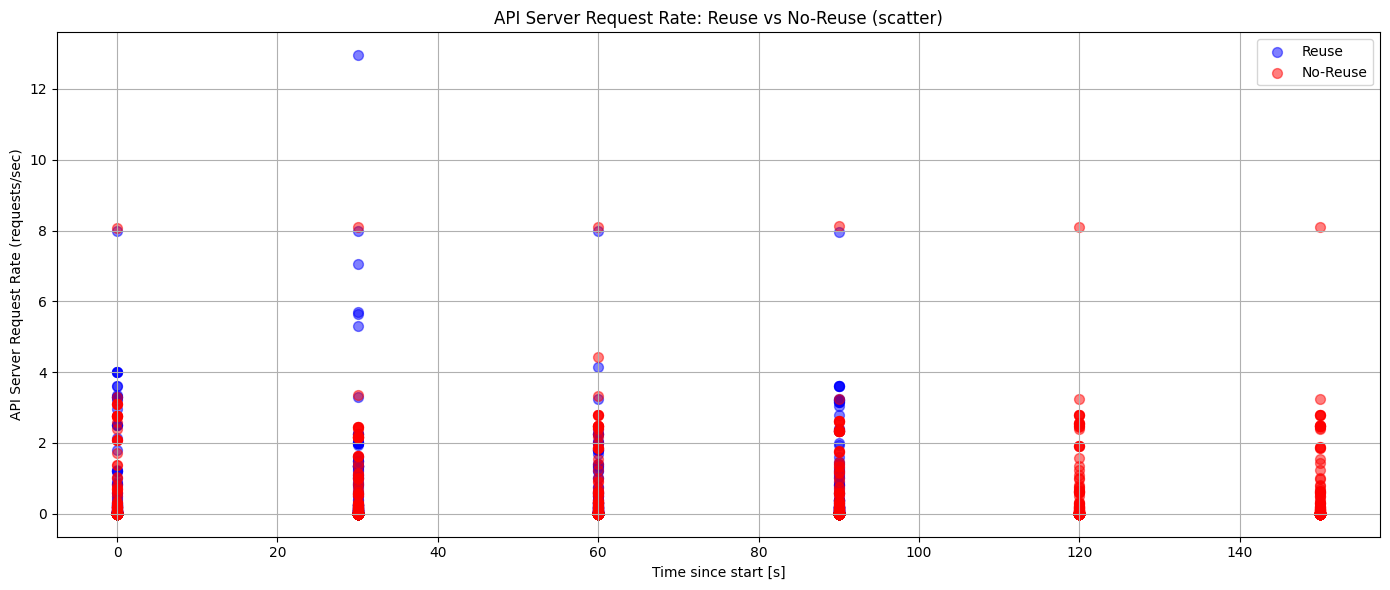

In [45]:
# apiserver_request_rate

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/apiserver_request_rate.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/apiserver_request_rate.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Scatter plot: apiserver request rate ---
plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["apiserver_request_rate"], 
            color='blue', alpha=0.5, s=50, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["apiserver_request_rate"], 
            color='red', alpha=0.5, s=50, label='No-Reuse')

plt.xlabel("Time since start [s]")
plt.ylabel("API Server Request Rate (requests/sec)")
plt.title("API Server Request Rate: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



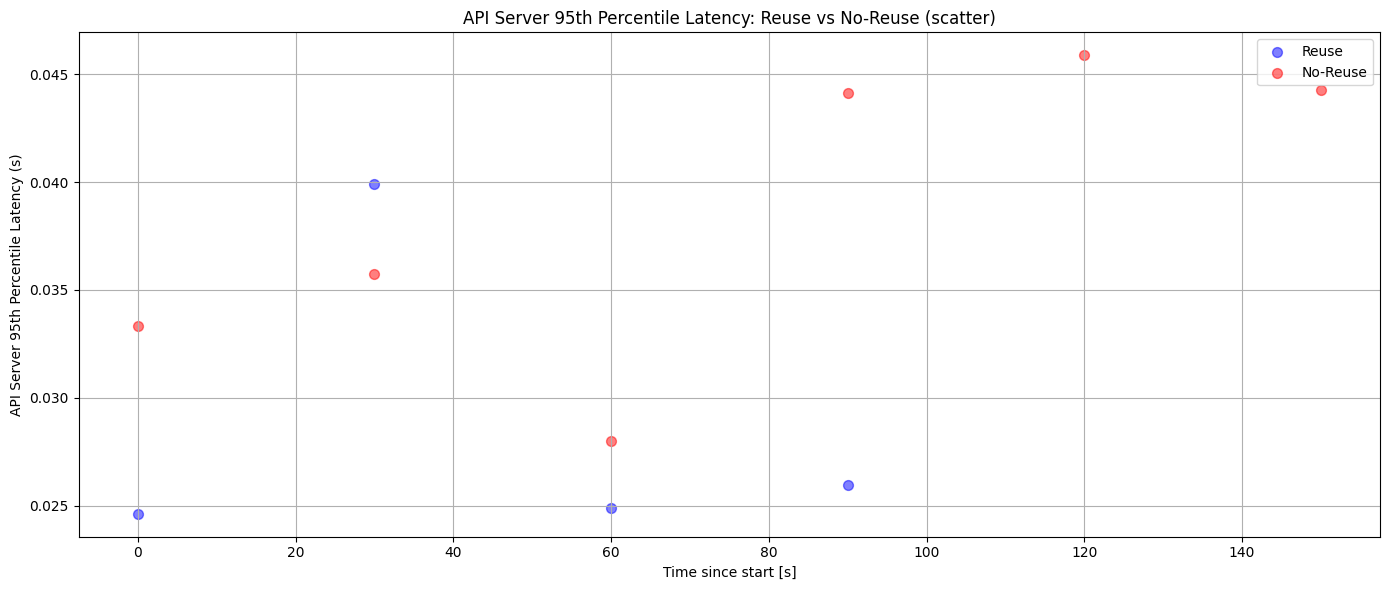

In [44]:
# apiserver_latency_95th

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/apiserver_latency_95th.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/apiserver_latency_95th.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Scatter plot: 95th percentile latency ---
plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["apiserver_latency_95th"], 
            color='blue', alpha=0.5, s=50, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["apiserver_latency_95th"], 
            color='red', alpha=0.5, s=50, label='No-Reuse')

plt.xlabel("Time since start [s]")
plt.ylabel("API Server 95th Percentile Latency (s)")
plt.title("API Server 95th Percentile Latency: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

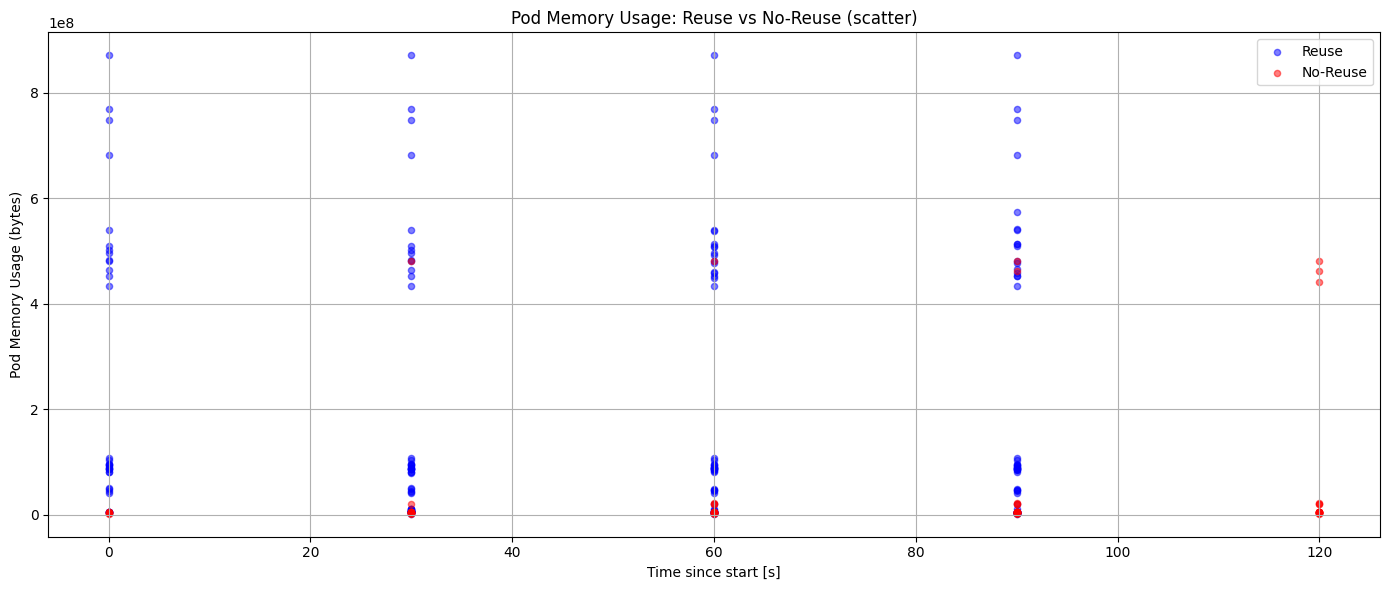

In [43]:
# pod_memory_usage
import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/pod_memory_usage.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/pod_memory_usage.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- --- 1. Scatter WITHOUT pod names ---
plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["pod_memory_usage"], 
            color='blue', alpha=0.5, s=20, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["pod_memory_usage"], 
            color='red', alpha=0.5, s=20, label='No-Reuse')
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Memory Usage (bytes)")
plt.title("Pod Memory Usage: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



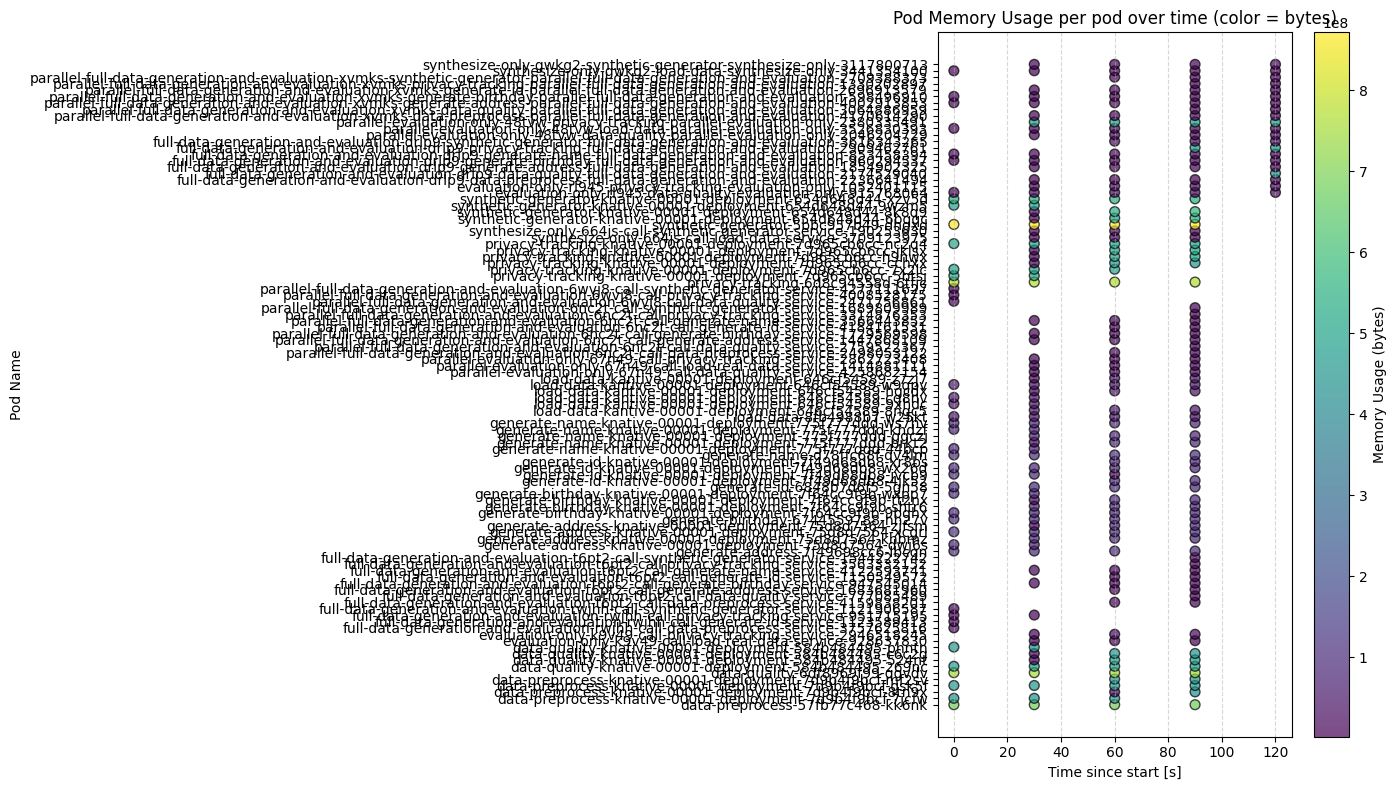

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/pod_memory_usage.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/pod_memory_usage.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# Combine data
df_reuse["setup"] = "Reuse"
df_no_reuse["setup"] = "No-Reuse"
df_all = pd.concat([df_reuse, df_no_reuse], ignore_index=True)

# Map pod to categorical Y-axis
pod_names = df_all["pod"].unique()
pod_map = {pod: i for i, pod in enumerate(pod_names)}
df_all["pod_idx"] = df_all["pod"].map(pod_map)

plt.figure(figsize=(14,8))
scatter = plt.scatter(
    df_all["t_sec"], df_all["pod_idx"], 
    c=df_all["pod_memory_usage"], 
    cmap="viridis", s=50, alpha=0.7, edgecolors='k'
)
plt.yticks(list(pod_map.values()), list(pod_map.keys()))
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Name")
plt.title("Pod Memory Usage per pod over time (color = bytes)")
cbar = plt.colorbar(scatter)
cbar.set_label("Memory Usage (bytes)")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


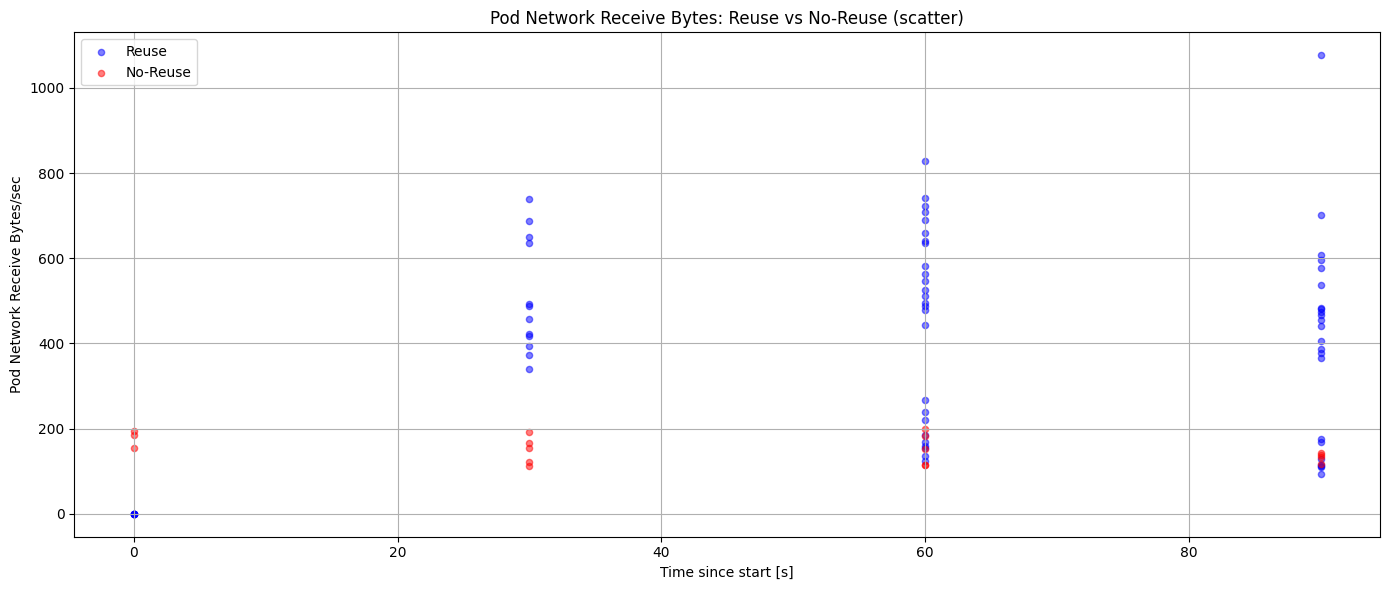

In [41]:
# pod_network_receive_bytes

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/pod_network_receive_bytes.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/pod_network_receive_bytes.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- 1. Scatter WITHOUT pod names ---
plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["pod_network_receive_bytes"], 
            color='blue', alpha=0.5, s=20, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["pod_network_receive_bytes"], 
            color='red', alpha=0.5, s=20, label='No-Reuse')
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Network Receive Bytes/sec")
plt.title("Pod Network Receive Bytes: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



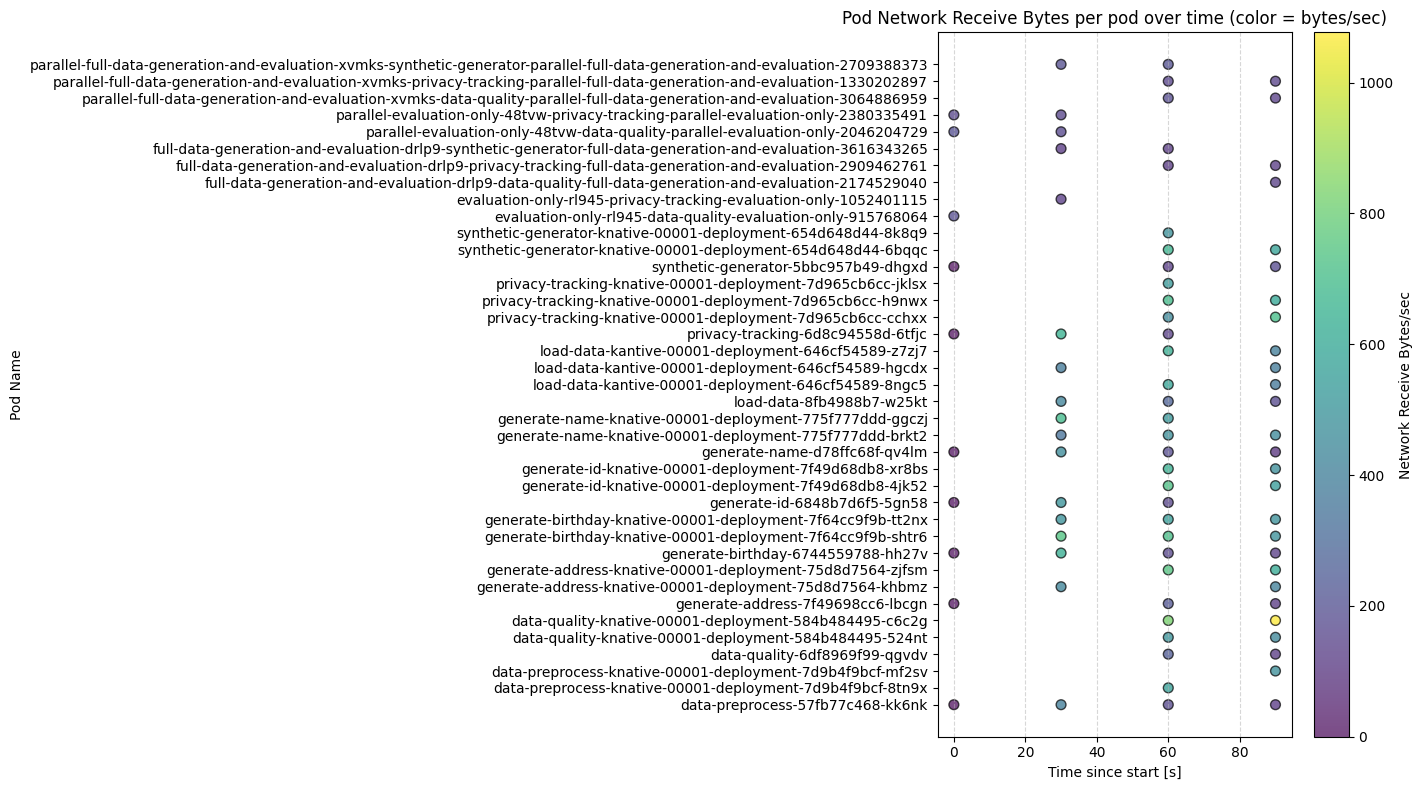

In [40]:
# pod_network_receive_bytes

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/pod_network_receive_bytes.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/pod_network_receive_bytes.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()
df_reuse["setup"] = "Reuse"
df_no_reuse["setup"] = "No-Reuse"
df_all = pd.concat([df_reuse, df_no_reuse], ignore_index=True)

# Map pod to categorical Y-axis
pod_names = df_all["pod"].unique()
pod_map = {pod: i for i, pod in enumerate(pod_names)}
df_all["pod_idx"] = df_all["pod"].map(pod_map)

plt.figure(figsize=(14,8))
scatter = plt.scatter(
    df_all["t_sec"], df_all["pod_idx"], 
    c=df_all["pod_network_receive_bytes"], 
    cmap="viridis", s=50, alpha=0.7, edgecolors='k'
)
plt.yticks(list(pod_map.values()), list(pod_map.keys()))
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Name")
plt.title("Pod Network Receive Bytes per pod over time (color = bytes/sec)")
cbar = plt.colorbar(scatter)
cbar.set_label("Network Receive Bytes/sec")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


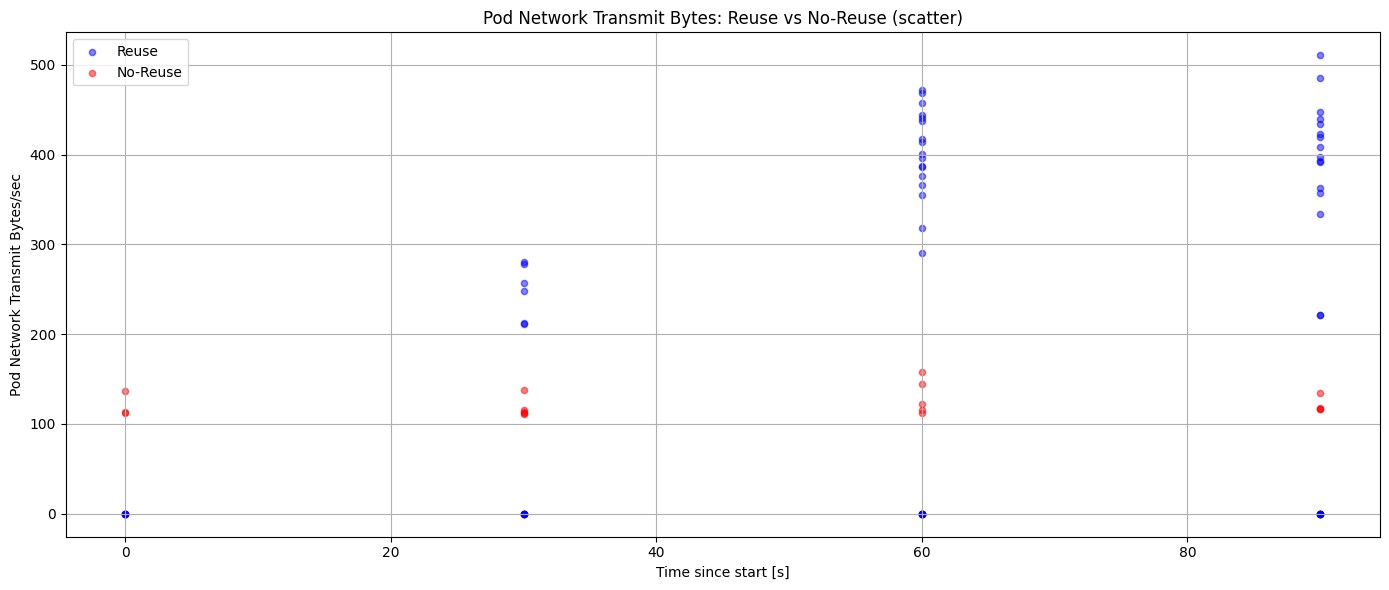

In [39]:
# pod_network_transmit_bytes
import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/pod_network_transmit_bytes.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/pod_network_transmit_bytes.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

plt.figure(figsize=(14,6))
plt.scatter(df_reuse["t_sec"], df_reuse["pod_network_transmit_bytes"], 
            color='blue', alpha=0.5, s=20, label='Reuse')
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["pod_network_transmit_bytes"], 
            color='red', alpha=0.5, s=20, label='No-Reuse')
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Network Transmit Bytes/sec")
plt.title("Pod Network Transmit Bytes: Reuse vs No-Reuse (scatter)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


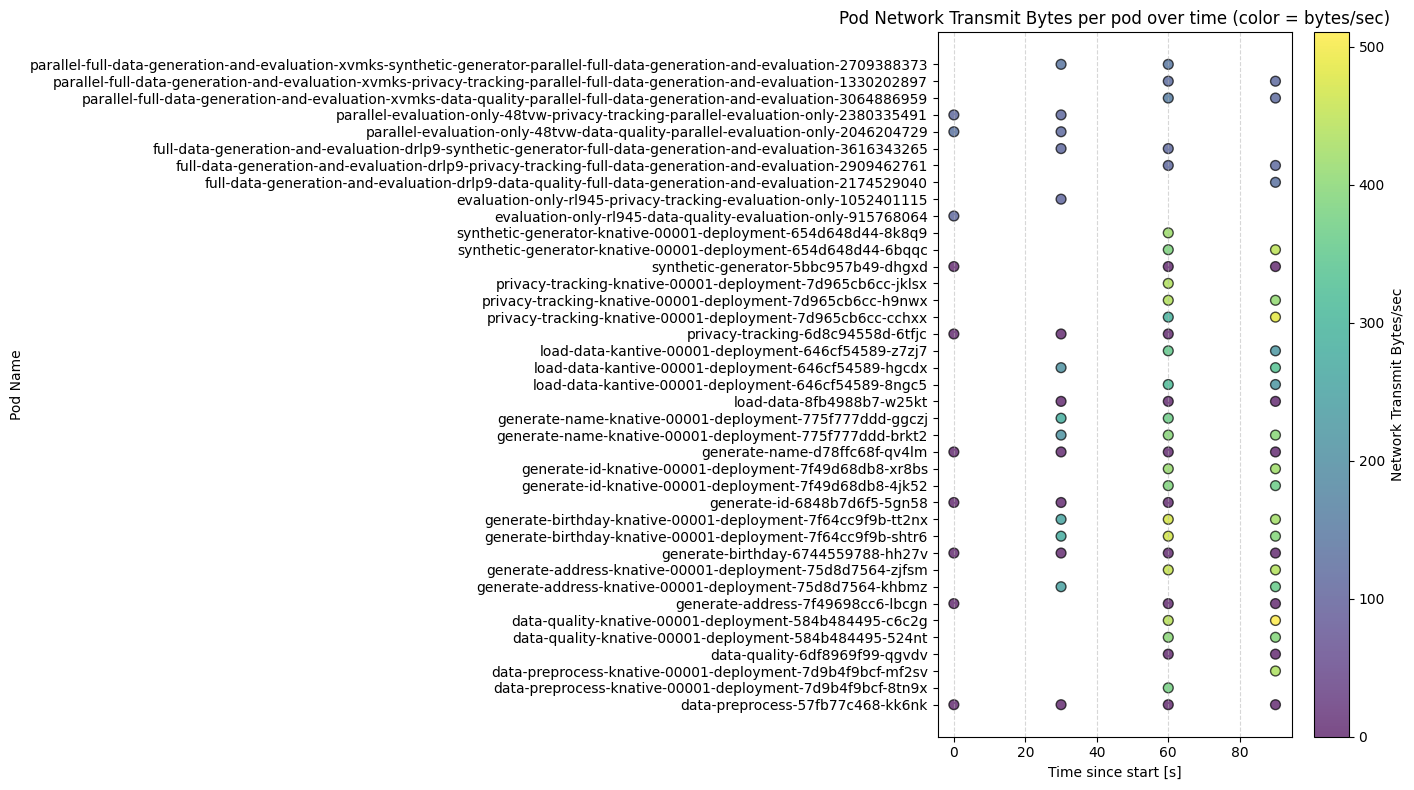

In [38]:
# pod_network_transmit_bytes
import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/pod_network_transmit_bytes.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/pod_network_transmit_bytes.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

df_reuse["setup"] = "Reuse"
df_no_reuse["setup"] = "No-Reuse"
df_all = pd.concat([df_reuse, df_no_reuse], ignore_index=True)

# Map pod to categorical Y-axis
pod_names = df_all["pod"].unique()
pod_map = {pod: i for i, pod in enumerate(pod_names)}
df_all["pod_idx"] = df_all["pod"].map(pod_map)

plt.figure(figsize=(14,8))
scatter = plt.scatter(
    df_all["t_sec"], df_all["pod_idx"], 
    c=df_all["pod_network_transmit_bytes"], 
    cmap="viridis", s=50, alpha=0.7, edgecolors='k'
)
plt.yticks(list(pod_map.values()), list(pod_map.keys()))
plt.xlabel("Time since start [s]")
plt.ylabel("Pod Name")
plt.title("Pod Network Transmit Bytes per pod over time (color = bytes/sec)")
cbar = plt.colorbar(scatter)
cbar.set_label("Network Transmit Bytes/sec")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

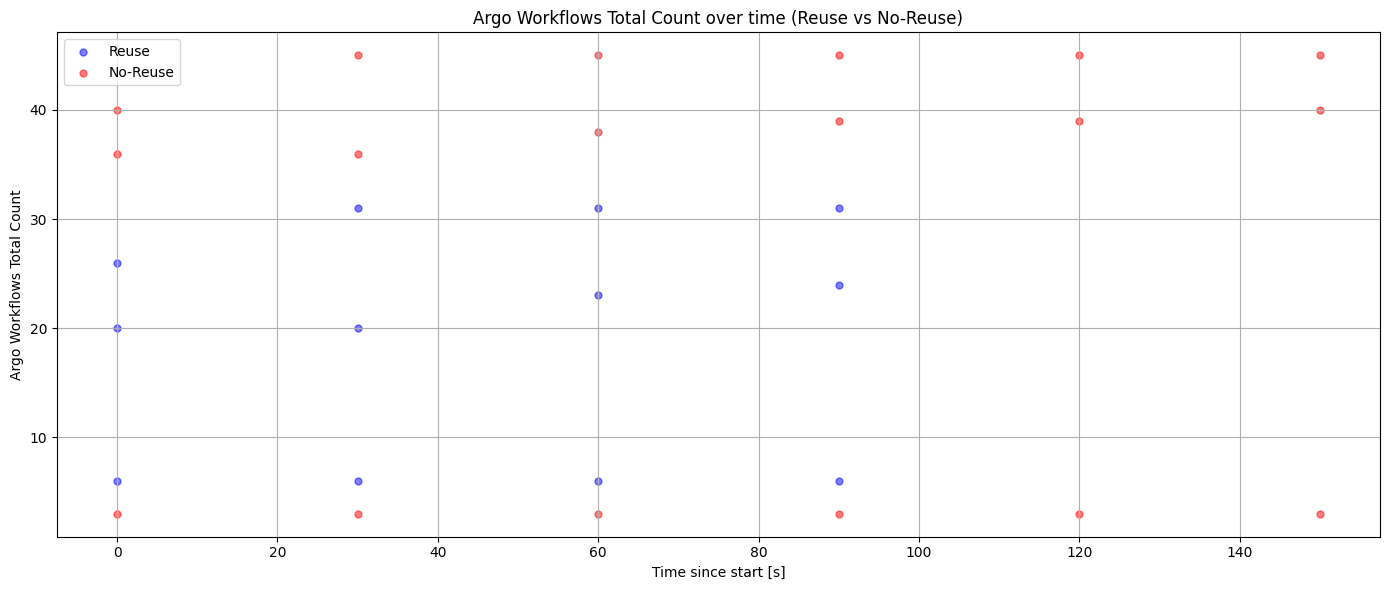

In [36]:
# argo_workflows_total_count: reuse vs no-reuse (t = 0 aligned)
import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/argo_workflows_total_count.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/argo_workflows_total_count.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

plt.figure(figsize=(14,6))
plt.scatter(
    df_reuse["t_sec"], df_reuse["argo_workflows_total_count"],
    color="blue", alpha=0.5, s=25, label="Reuse"
)
plt.scatter(
    df_no_reuse["t_sec"], df_no_reuse["argo_workflows_total_count"],
    color="red", alpha=0.5, s=25, label="No-Reuse"
)

plt.xlabel("Time since start [s]")
plt.ylabel("Argo Workflows Total Count")
plt.title("Argo Workflows Total Count over time (Reuse vs No-Reuse)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



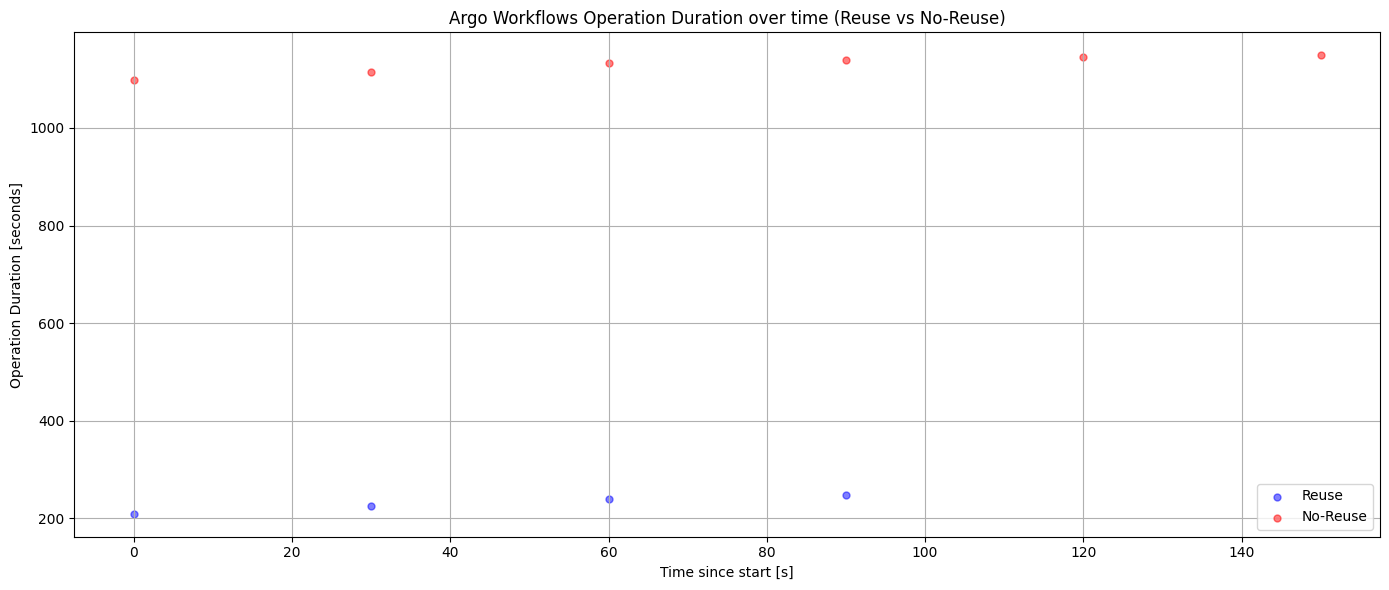

In [35]:
# argo_workflows_operation_duration_seconds: reuse vs no-reuse (t = 0 aligned)

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/argo_workflows_operation_duration_seconds.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/argo_workflows_operation_duration_seconds.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps and normalize to t=0 ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()
plt.figure(figsize=(14,6))

plt.scatter(
    df_reuse["t_sec"],
    df_reuse["argo_workflows_operation_duration_seconds"],
    color="blue",
    alpha=0.5,
    s=25,
    label="Reuse"
)

plt.scatter(
    df_no_reuse["t_sec"],
    df_no_reuse["argo_workflows_operation_duration_seconds"],
    color="red",
    alpha=0.5,
    s=25,
    label="No-Reuse"
)

plt.xlabel("Time since start [s]")
plt.ylabel("Operation Duration [seconds]")
plt.title("Argo Workflows Operation Duration over time (Reuse vs No-Reuse)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [ ]:
# argo_workflows_completed_total: reuse vs no-reuse (t = 0 aligned)


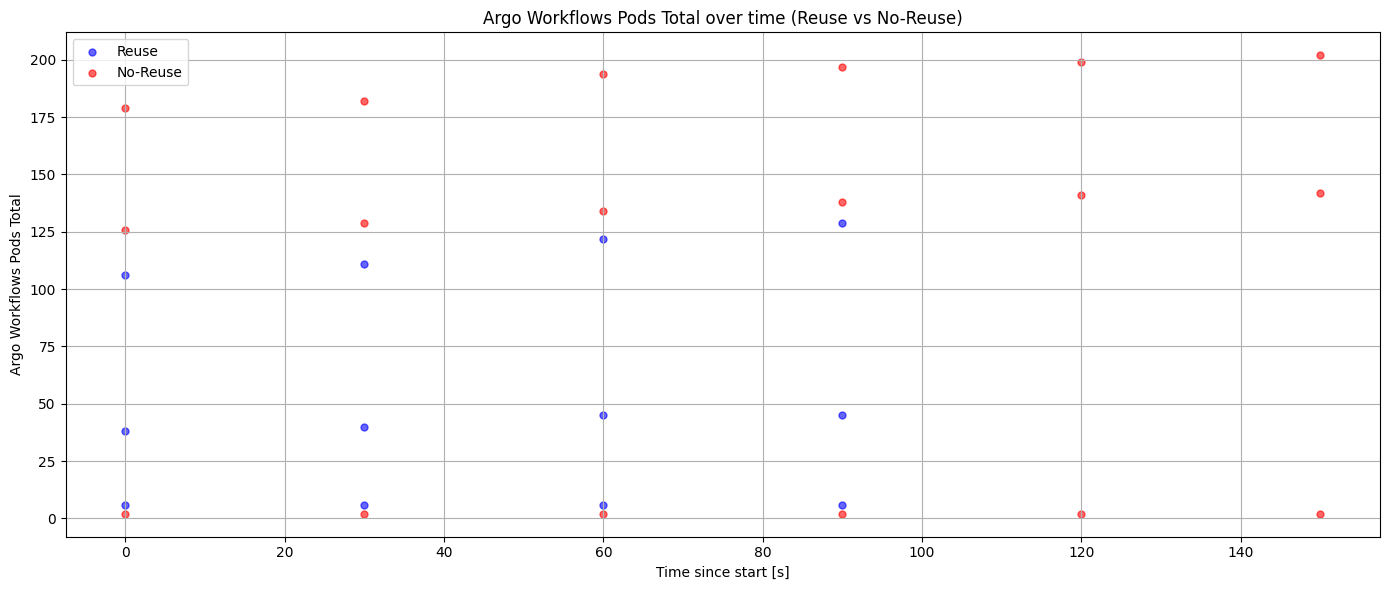

In [34]:
# argo_workflows_pods_total: reuse vs no-reuse (t = 0 aligned)

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/argo_workflows_pods_total.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/argo_workflows_pods_total.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

# --- Normalize time (t = 0) ---
df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Plot ---
plt.figure(figsize=(14,6))

plt.scatter(
    df_reuse["t_sec"],
    df_reuse["argo_workflows_pods_total"],
    s=25,
    alpha=0.6,
    color="blue",
    label="Reuse"
)

plt.scatter(
    df_no_reuse["t_sec"],
    df_no_reuse["argo_workflows_pods_total"],
    s=25,
    alpha=0.6,
    color="red",
    label="No-Reuse"
)

plt.xlabel("Time since start [s]")
plt.ylabel("Argo Workflows Pods Total")
plt.title("Argo Workflows Pods Total over time (Reuse vs No-Reuse)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


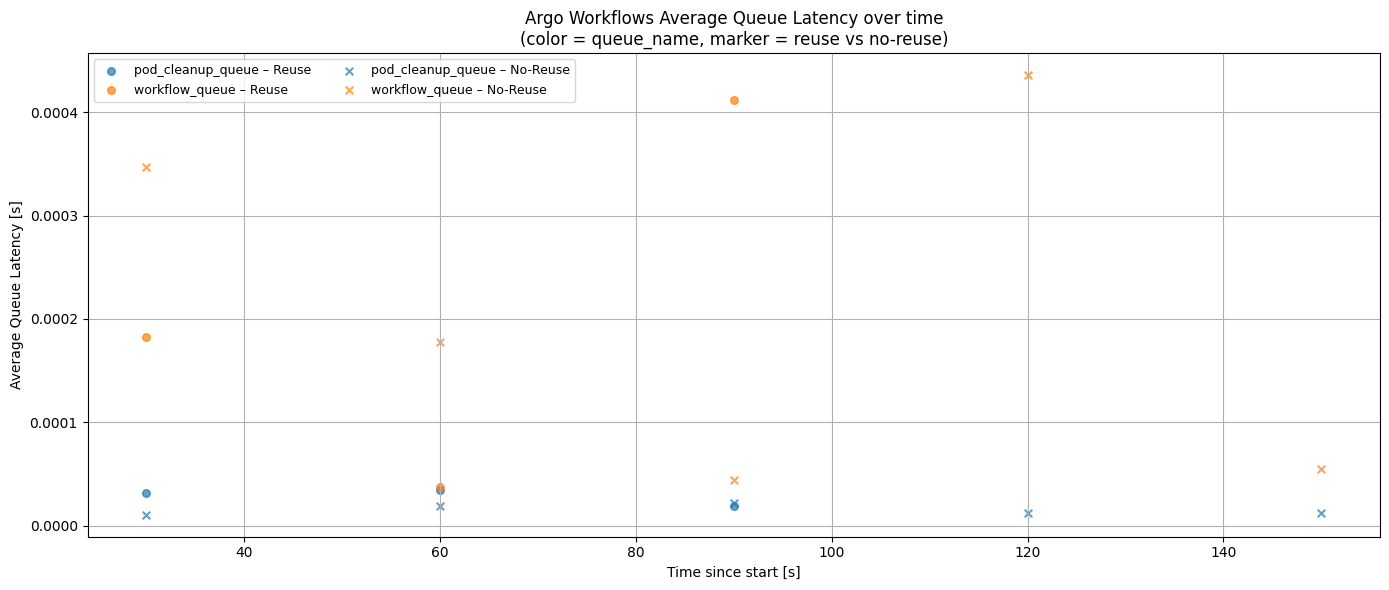

In [33]:
# argo_workflows_average_queue_latency: reuse vs no-reuse (t = 0 aligned)

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/argo_workflows_average_queue_latency.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/argo_workflows_average_queue_latency.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

# --- Normalize time (t = 0) ---
df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Tag setup ---
df_reuse["setup"] = "Reuse"
df_no_reuse["setup"] = "No-Reuse"

df_all = pd.concat([df_reuse, df_no_reuse], ignore_index=True)

# --- Color map per queue ---
queue_names = df_all["queue_name"].unique()
colors = plt.cm.tab10.colors
queue_color = {q: colors[i % len(colors)] for i, q in enumerate(queue_names)}

# --- Marker per setup ---
marker_map = {
    "Reuse": "o",
    "No-Reuse": "x"
}

# --- Plot ---
plt.figure(figsize=(14,6))

for setup in ["Reuse", "No-Reuse"]:
    df_s = df_all[df_all["setup"] == setup]
    for q in queue_names:
        df_q = df_s[df_s["queue_name"] == q]
        plt.scatter(
            df_q["t_sec"],
            df_q["argo_workflows_average_queue_latency"],
            s=30,
            alpha=0.7,
            color=queue_color[q],
            marker=marker_map[setup],
            label=f"{q} – {setup}"
        )

plt.xlabel("Time since start [s]")
plt.ylabel("Average Queue Latency [s]")
plt.title("Argo Workflows Average Queue Latency over time\n(color = queue_name, marker = reuse vs no-reuse)")
plt.grid(True)

# --- De-duplicate legend entries ---
handles, labels = plt.gca().get_legend_handles_labels()
unique = dict(zip(labels, handles))
plt.legend(unique.values(), unique.keys(), fontsize=9, ncol=2)

plt.tight_layout()
plt.show()


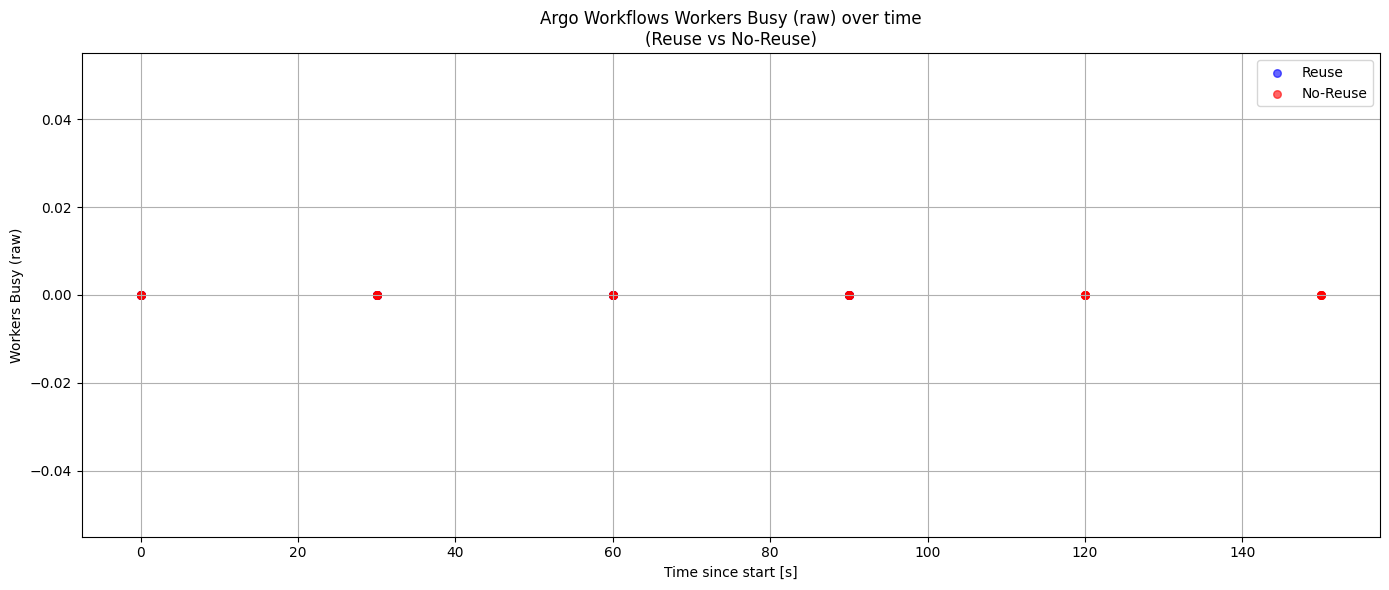

In [32]:
# argo_workflows_workers_busy_raw: reuse vs no-reuse (t = 0 aligned)
###### useless ##########

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/argo_workflows_workers_busy_raw.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/argo_workflows_workers_busy_raw.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

# --- Normalize time (t = 0) ---
df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Plot ---
plt.figure(figsize=(14,6))

plt.scatter(
    df_reuse["t_sec"],
    df_reuse["argo_workflows_workers_busy_raw"],
    s=30,
    alpha=0.6,
    color="blue",
    label="Reuse"
)

plt.scatter(
    df_no_reuse["t_sec"],
    df_no_reuse["argo_workflows_workers_busy_raw"],
    s=30,
    alpha=0.6,
    color="red",
    label="No-Reuse"
)

plt.xlabel("Time since start [s]")
plt.ylabel("Workers Busy (raw)")
plt.title("Argo Workflows Workers Busy (raw) over time\n(Reuse vs No-Reuse)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


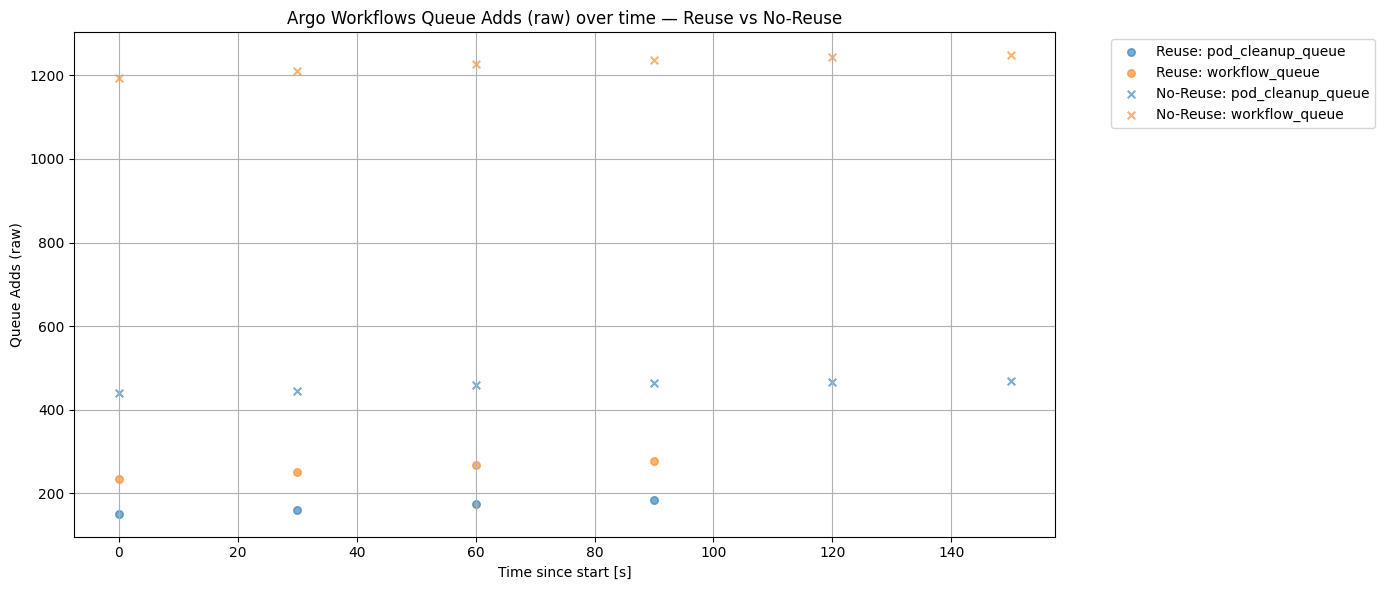

In [31]:
# argo_workflows_queue_adds_raw: reuse vs no-reuse (t = 0 aligned)

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/argo_workflows_queue_adds_raw.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/argo_workflows_queue_adds_raw.csv"

# --- Load CSVs ---
df_reuse = pd.read_csv(reuse_file)
df_no_reuse = pd.read_csv(no_reuse_file)

# --- Convert timestamps ---
df_reuse["timestamp"] = pd.to_datetime(df_reuse["timestamp"])
df_no_reuse["timestamp"] = pd.to_datetime(df_no_reuse["timestamp"])

# --- Normalize time (t = 0) ---
df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Optional: map queue_name to colors ---
queue_names = df_reuse["queue_name"].unique().tolist()
queue_colors = {q: c for q, c in zip(queue_names, plt.cm.tab10.colors)}

# --- Plot ---
plt.figure(figsize=(14,6))

# Reuse
for queue in df_reuse["queue_name"].unique():
    subset = df_reuse[df_reuse["queue_name"] == queue]
    plt.scatter(subset["t_sec"], subset["argo_workflows_queue_adds_raw"], 
                s=30, alpha=0.6, color=queue_colors[queue], marker="o", label=f"Reuse: {queue}")

# No-Reuse
for queue in df_no_reuse["queue_name"].unique():
    subset = df_no_reuse[df_no_reuse["queue_name"] == queue]
    plt.scatter(subset["t_sec"], subset["argo_workflows_queue_adds_raw"], 
                s=30, alpha=0.6, color=queue_colors.get(queue, "gray"), marker="x", label=f"No-Reuse: {queue}")

plt.xlabel("Time since start [s]")
plt.ylabel("Queue Adds (raw)")
plt.title("Argo Workflows Queue Adds (raw) over time — Reuse vs No-Reuse")
plt.legend(bbox_to_anchor=(1.05,1), loc="upper left")  # legend outside
plt.grid(True)
plt.tight_layout()
plt.show()


In [30]:
# argo_workflows_k8s_requests_raw: reuse vs no-reuse (t = 0 aligned)

import pandas as pd
import matplotlib.pyplot as plt

# --- File paths ---
reuse_file = "Knative-reuse_1000_baremetal_2026_01_27_11_55_03_b297304d/data/argo_workflows_k8s_requests_raw.csv"
no_reuse_file = "no-reuse_1000_baremetal_2026_01_20_23_11_49_976c96ea/data/argo_workflows_k8s_requests_raw.csv"

# --- Load CSVs ---
def load_csv(file):
    df = pd.read_csv(file)
    # Remove duplicate columns (keep first occurrence)
    df = df.loc[:, ~df.columns.duplicated()]
    return df

df_reuse = load_csv(reuse_file)
df_no_reuse = load_csv(no_reuse_file)

# --- Choose timestamp column ---
for df in [df_reuse, df_no_reuse]:
    timestamp_cols = [c for c in df.columns if "timestamp" in c.lower()]
    df["timestamp"] = pd.to_datetime(df[timestamp_cols[0]])

# --- Normalize start time ---
df_reuse["t_sec"] = (df_reuse["timestamp"] - df_reuse["timestamp"].min()).dt.total_seconds()
df_no_reuse["t_sec"] = (df_no_reuse["timestamp"] - df_no_reuse["timestamp"].min()).dt.total_seconds()

# --- Plot ---
plt.figure(figsize=(12,6))

# Reuse = circles
plt.scatter(df_reuse["t_sec", df_reuse["argo_workflows_k8s_requests_raw"], 
            s=50, alpha=0.6, marker="o", color="blue", label="Reuse")

# No-Reuse = crosses
plt.scatter(df_no_reuse["t_sec"], df_no_reuse["argo_workflows_k8s_requests_raw"], 
            s=50, alpha=0.6, marker="x", color="red", label="No-Reuse")

plt.xlabel("Time since start [s]")
plt.ylabel("Argo K8s Requests (raw)")
plt.title("Argo Workflows K8s Requests (raw) — Reuse vs No-Reuse")
plt.legend()
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

SyntaxError: invalid syntax (2730126086.py, line 34)